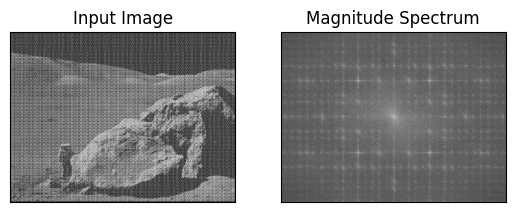

In [63]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

img = cv.imread('periodic_noise.JPG', 0)

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

spectrum = 20 * np.log(
    cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1
)

plt.subplot(122), plt.imshow(spectrum, cmap='gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

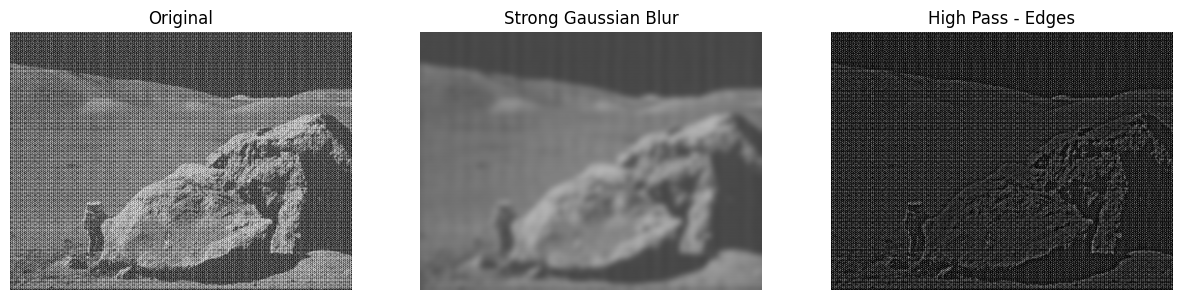

In [64]:
#Сильное размытие
blur = cv.GaussianBlur(img, (31, 31), 7)

#Выделение контуров
high = cv.subtract(img, blur)
high = cv.normalize(high, None, 0, 255, cv.NORM_MINMAX)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original')
plt.axis('off')

plt.subplot(132)
plt.imshow(blur, cmap='gray', vmin=0, vmax=255)
plt.title('Strong Gaussian Blur')
plt.axis('off')

plt.subplot(133)
plt.imshow(high, cmap='gray', vmin=0, vmax=255)
plt.title('High Pass - Edges')
plt.axis('off')

plt.show()

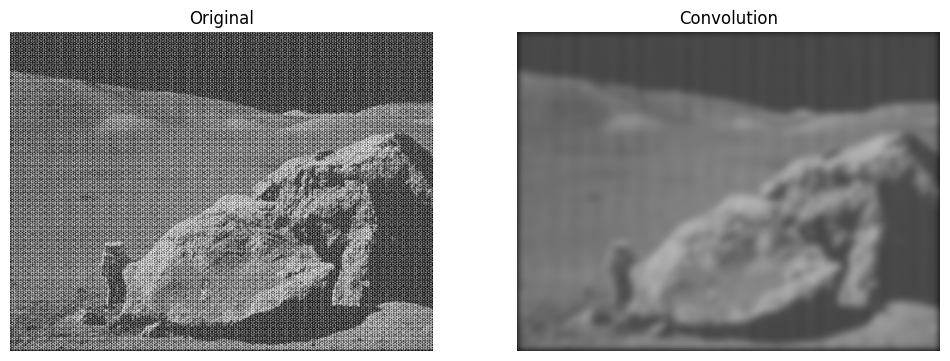

In [65]:
#большое гауссово ядро
kernel = cv.getGaussianKernel(31, 7)
kernel = kernel @ kernel.T

h, w = img.shape
kh, kw = kernel.shape

a = cv.getOptimalDFTSize(h + kh - 1)
b = cv.getOptimalDFTSize(w + kw - 1)

img_pad = np.zeros((a, b), np.float32)
ker_pad = np.zeros((a, b), np.float32)

img_pad[:h, :w] = img
ker_pad[:kh, :kw] = kernel

f1 = cv.dft(img_pad, flags=cv.DFT_COMPLEX_OUTPUT)
f2 = cv.dft(ker_pad, flags=cv.DFT_COMPLEX_OUTPUT)

f = cv.mulSpectrums(f1, f2, 0)

res = cv.idft(f, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)
res = res[kh//2:kh//2+h, kw//2:kw//2+w]

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original')
plt.axis('off')

plt.subplot(122)
plt.imshow(res, cmap='gray', vmin=0, vmax=255)
plt.title('Convolution')
plt.axis('off')

plt.show()

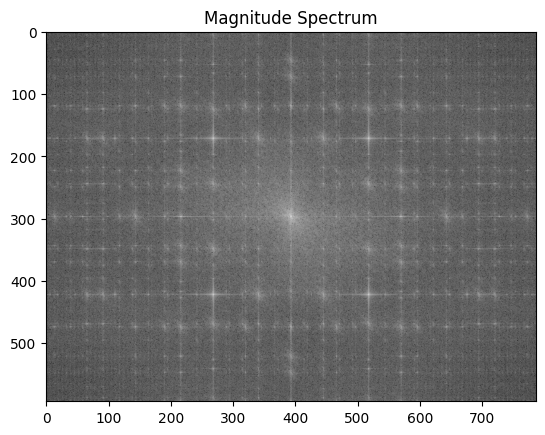

In [66]:
mask = np.ones((img.shape[0], img.shape[1], 2), np.float32)

plt.imshow(spectrum, cmap='gray')
plt.title('Magnitude Spectrum')
plt.show()

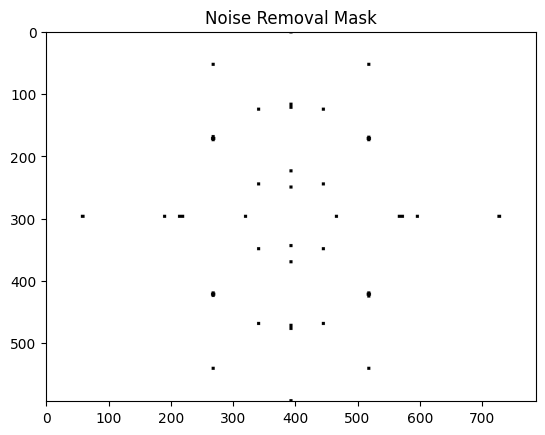

In [67]:
h, w = img.shape

#Амплитудный спектр
spectrum = cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])

spec_copy = spectrum.copy()
spec_copy[h//2-20:h//2+20, w//2-20:w//2+20] = 0

#80 самых ярких точек
top_indices = np.argsort(spec_copy.ravel())[-80:]

mask = np.ones((h, w), np.float32)

for idx in top_indices:
    y, x = np.unravel_index(idx, (h, w))

    sy = (2 * (h//2) - y) % h
    sx = (2 * (w//2) - x) % w

    mask[max(0, y-2):min(h, y+3),
         max(0, x-2):min(w, x+3)] = 0

    mask[max(0, sy-2):min(h, sy+3),
         max(0, sx-2):min(w, sx+3)] = 0

plt.imshow(mask, cmap='gray')
plt.title('Noise Removal Mask')
plt.show()

dft_shift[:, :, 0] *= mask
dft_shift[:, :, 1] *= mask

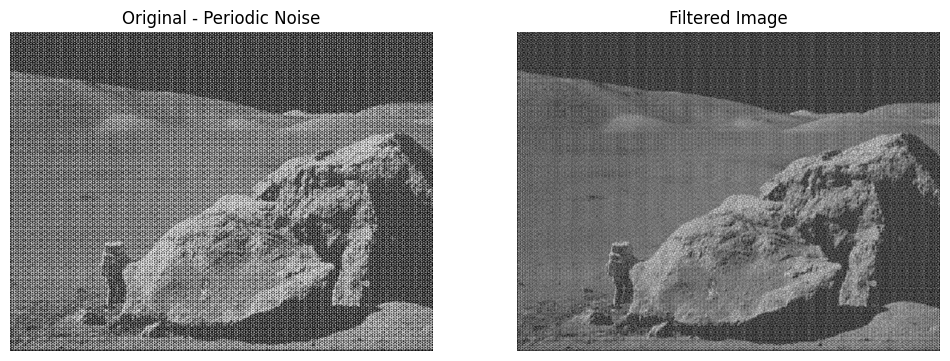

In [68]:
# Обратное преобразование Фурье
dft_unshift = np.fft.ifftshift(dft_shift)

filtered_dft = cv.idft(
    dft_unshift,
    flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT
)

filtered = cv.normalize(
    np.abs(filtered_dft), None, 0, 255, cv.NORM_MINMAX
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original - Periodic Noise')
plt.axis('off')

plt.subplot(122)
plt.imshow(filtered, cmap='gray', vmin=0, vmax=255)
plt.title('Filtered Image')
plt.axis('off')

plt.show()